# Telco Customer Churn - Five-Model Comparison
### DSE ZG565 Machine Learning - Assignment 2

This notebook trains and compares the five classifiers from the course syllabus on the
**Telco Customer Churn** dataset and is the version intended for execution on the
**BITS Virtual Lab**.

The five models compared:

- Logistic Regression
- Decision Tree (entropy)
- k-Nearest Neighbour
- Support Vector Machine (RBF)
- Gaussian Naive Bayes

The task is **binary classification**: predict whether a customer will *churn* (leave the
telecom company) from 19 account, service and billing features. Each model is wrapped in a
pipeline that standardises the numeric features and one-hot encodes the categorical ones,
and the six required metrics are reported on the churn (`Yes`) class.

## 1. Imports

In [1]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    make_scorer, matthews_corrcoef, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TARGET = "Churn"
POS_LABEL = "Yes"
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
print("Libraries loaded.")

Libraries loaded.


## 2. Load the data

The cleaned train / test splits are shipped in the repository (`data/train_data.csv` and
`test_data.csv`). If they are not present, the raw dataset is downloaded from the IBM public
mirror and cleaned on the fly so the notebook is self-contained.

In [2]:
import os
HERE = os.getcwd()
# Works whether the notebook is launched from model/ or the repo root.
ROOT = HERE if os.path.exists(os.path.join(HERE, "test_data.csv")) else os.path.dirname(HERE)

train_path = os.path.join(ROOT, "data", "train_data.csv")
test_path = os.path.join(ROOT, "test_data.csv")

if os.path.exists(train_path) and os.path.exists(test_path):
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)
    print("Loaded shipped splits.")
else:
    url = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
           "master/data/Telco-Customer-Churn.csv")
    df = pd.read_csv(url).drop(columns=["customerID"])
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
    df = df.drop_duplicates().reset_index(drop=True)
    from sklearn.model_selection import train_test_split
    train_df, test_df = train_test_split(
        df, test_size=0.20, random_state=RANDOM_STATE, stratify=df[TARGET])
    print("Downloaded and cleaned the raw dataset.")

print(f"Train: {train_df.shape}   Test: {test_df.shape}")
train_df.head()

Loaded shipped splits.
Train: (5608, 20)   Test: (1402, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,Yes,No,No,16,Yes,Yes,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,54.10,889.00,No
1,Female,No,No,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,25.25,25.25,No
2,Female,No,Yes,No,65,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),107.65,7082.85,No
3,Female,No,No,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,No,Mailed check,24.40,24.40,No
4,Male,Yes,Yes,No,36,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),85.25,3132.75,Yes


## 3. Exploratory data analysis

In [3]:
feature_names = [c for c in train_df.columns if c != TARGET]
print(f"Features ({len(feature_names)}):")
for c in feature_names:
    print("  ", c)
print(f"\nChurn rate (train): {(train_df[TARGET]=='Yes').mean():.1%}")

Features (19):
   gender
   SeniorCitizen
   Partner
   Dependents
   tenure
   PhoneService
   MultipleLines
   InternetService
   OnlineSecurity
   OnlineBackup
   DeviceProtection
   TechSupport
   StreamingTV
   StreamingMovies
   Contract
   PaperlessBilling
   PaymentMethod
   MonthlyCharges
   TotalCharges

Churn rate (train): 26.5%


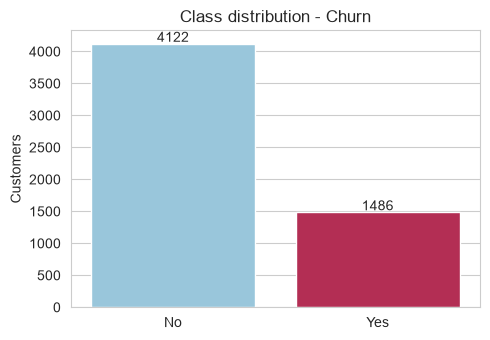

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
order = ["No", "Yes"]
counts = train_df[TARGET].value_counts().reindex(order)
sns.barplot(x=order, y=counts.values, hue=order, palette=["#8ecae6", "#c9184a"],
            legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, str(v), ha="center")
ax.set_title("Class distribution - Churn")
ax.set_ylabel("Customers")
plt.tight_layout(); plt.show()

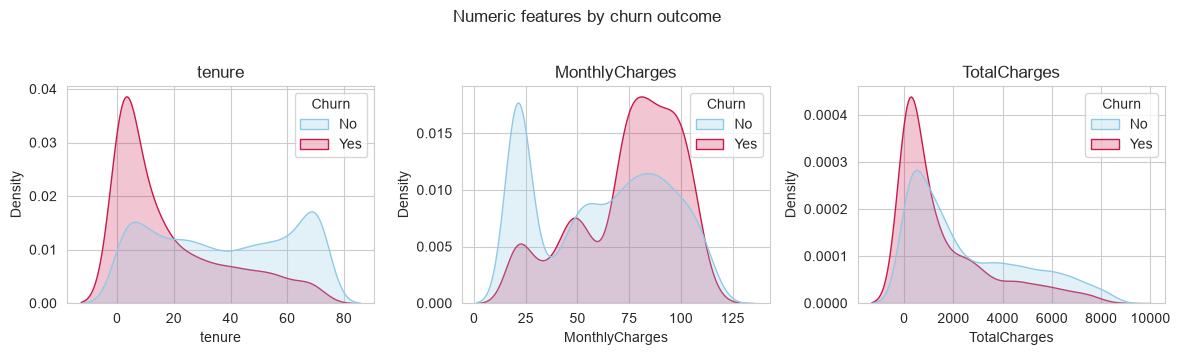

In [5]:
# Numeric features split by churn outcome.
numeric = train_df[feature_names].select_dtypes(include="number").columns.tolist()
fig, axes = plt.subplots(1, len(numeric), figsize=(4 * len(numeric), 3.4))
for ax, col in zip(axes, numeric):
    sns.kdeplot(data=train_df, x=col, hue=TARGET, fill=True,
                palette=["#8ecae6", "#c9184a"], common_norm=False, ax=ax)
    ax.set_title(col)
fig.suptitle("Numeric features by churn outcome", y=1.03)
plt.tight_layout(); plt.show()

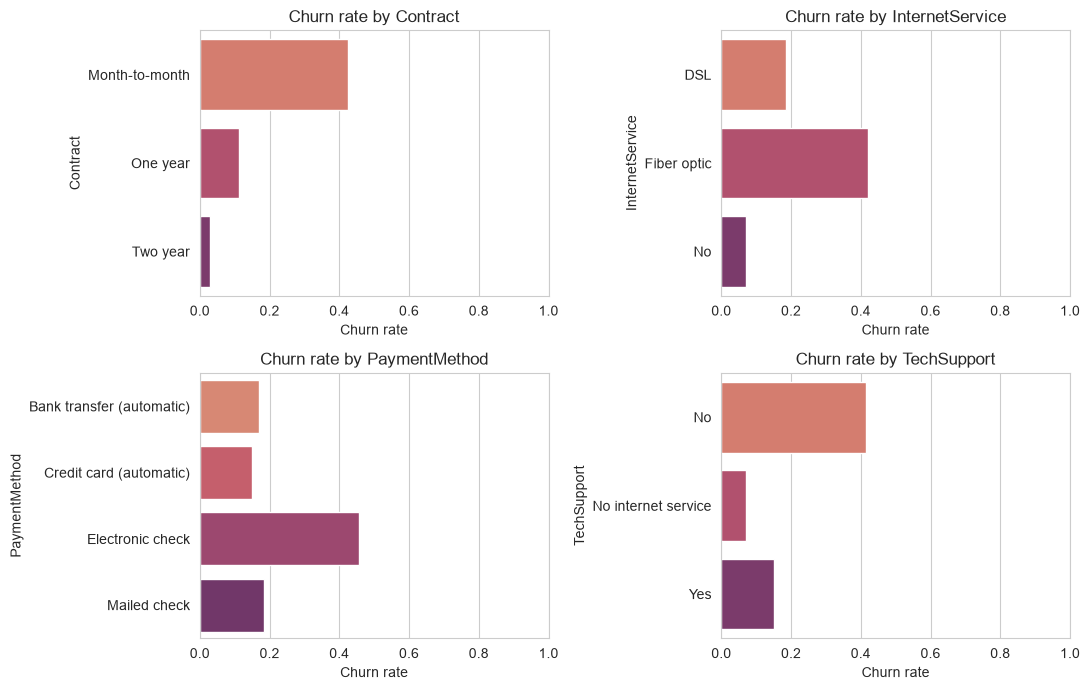

In [6]:
# Churn rate across the most telling categorical features.
cat_show = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), cat_show):
    rate = train_df.groupby(col)[TARGET].apply(lambda s: (s == "Yes").mean())
    sns.barplot(x=rate.values, y=rate.index, hue=rate.index, palette="flare",
                legend=False, ax=ax)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

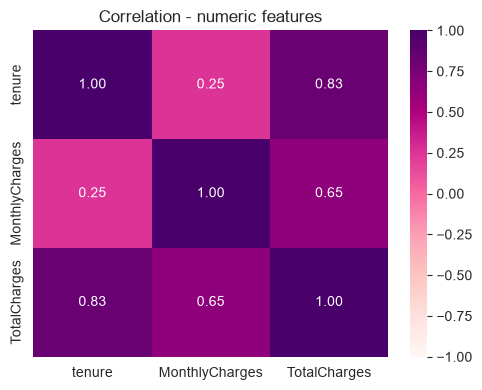

In [7]:
# Correlation among numeric features.
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(train_df[numeric].corr(), annot=True, fmt=".2f", cmap="RdPu",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation - numeric features")
plt.tight_layout(); plt.show()

## 4. Preprocessing

A single `ColumnTransformer` standardises the three numeric features and one-hot encodes the
sixteen categorical ones. Wrapping it inside each model's `Pipeline` means the scaler and
encoder are fitted **only on the training folds** during cross-validation and replayed
identically at prediction time - no leakage from the test set.

In [8]:
X_train, y_train = train_df[feature_names], train_df[TARGET]
X_test, y_test = test_df[feature_names], test_df[TARGET]

numeric = X_train.select_dtypes(include="number").columns.tolist()
categorical = [c for c in feature_names if c not in numeric]

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])

print(f"Numeric ({len(numeric)}):     {numeric}")
print(f"Categorical ({len(categorical)}): {categorical}")
enc_cols = make_preprocessor().fit(X_train).get_feature_names_out()
print(f"\nColumns after encoding: {len(enc_cols)}")

Numeric (3):     ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']



Columns after encoding: 46


## 5. Train and tune the five models

Each model is tuned with 5-fold cross-validation, scored by **F1 on the churn class**.
`class_weight='balanced'` is offered to the models that support it, because the data is
imbalanced (~27% churn) and recall on churners matters for a retention campaign.

In [9]:
F1_SCORER = make_scorer(f1_score, pos_label=POS_LABEL)

MODEL_SPECS = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        {"clf__C": [0.1, 1.0, 10.0], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE),
        {"clf__max_depth": [None, 5, 10, 15], "clf__min_samples_leaf": [1, 5, 20],
         "clf__class_weight": [None, "balanced"]}),
    "kNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 31], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]}),
    "Support Vector Machine": (
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"clf__C": [1.0, 10.0], "clf__class_weight": [None, "balanced"]}),
}

def evaluate(model, X, y):
    pred = model.predict(X)
    pos = list(model.classes_).index(POS_LABEL)
    proba = model.predict_proba(X)[:, pos]
    return {
        "Accuracy": accuracy_score(y, pred),
        "AUC": roc_auc_score(y == POS_LABEL, proba),
        "Precision": precision_score(y, pred, pos_label=POS_LABEL, zero_division=0),
        "Recall": recall_score(y, pred, pos_label=POS_LABEL, zero_division=0),
        "F1": f1_score(y, pred, pos_label=POS_LABEL, zero_division=0),
        "MCC": matthews_corrcoef(y, pred),
    }

fitted, rows = {}, []
for name, (est, grid) in MODEL_SPECS.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    search = GridSearchCV(pipe, grid, cv=5, scoring=F1_SCORER, n_jobs=-1)
    t0 = time.time(); search.fit(X_train, y_train); dt = time.time() - t0
    fitted[name] = search.best_estimator_
    m = evaluate(search.best_estimator_, X_test, y_test)
    rows.append({"Model": name, **m})
    bp = {k.replace('clf__', ''): v for k, v in search.best_params_.items()}
    print(f"{name:24} CV-F1={search.best_score_:.4f}  fit={dt:4.1f}s  {bp}")

Logistic Regression      CV-F1=0.6316  fit=17.5s  {'C': 10.0, 'class_weight': 'balanced'}


Decision Tree            CV-F1=0.6217  fit= 4.6s  {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 20}


kNN                      CV-F1=0.6042  fit= 2.6s  {'n_neighbors': 31, 'weights': 'uniform'}


Naive Bayes              CV-F1=0.5938  fit= 0.7s  {'var_smoothing': 1e-09}


Support Vector Machine   CV-F1=0.6247  fit=42.7s  {'C': 1.0, 'class_weight': 'balanced'}


## 6. Comparison table (hold-out test set)

In [10]:
results = pd.DataFrame(rows).set_index("Model")[
    ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]]
results.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.7425,0.8467,0.5088,0.7763,0.6147,0.4555
Decision Tree,0.7582,0.8312,0.5309,0.7412,0.6187,0.4620
kNN,0.7939,0.8361,0.6228,0.5606,0.5901,0.4540
Naive Bayes,0.7019,0.8138,0.4648,0.8356,0.5973,0.4322
Support Vector Machine,0.7525,0.8215,0.5220,0.7682,0.6216,0.4659


In [11]:
styler = results.round(4).style.highlight_max(axis=0, color="#f7cad0")
styler

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.742500,0.846700,0.508800,0.776300,0.614700,0.455500
Decision Tree,0.758200,0.831200,0.530900,0.741200,0.618700,0.462000
kNN,0.793900,0.836100,0.622800,0.560600,0.590100,0.454000
Naive Bayes,0.701900,0.813800,0.464800,0.835600,0.597300,0.432200
Support Vector Machine,0.752500,0.821500,0.522000,0.768200,0.621600,0.465900


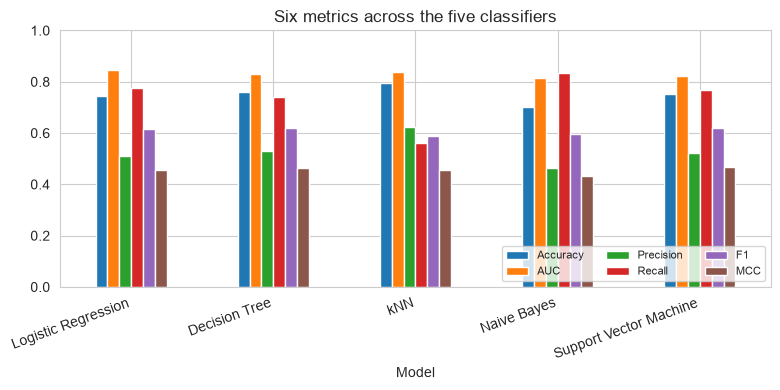

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
results[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]].plot.bar(ax=ax)
ax.set_title("Six metrics across the five classifiers")
ax.set_ylim(0, 1); ax.legend(loc="lower right", ncol=3, fontsize=8)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

## 7. Confusion matrix and report - best model by churn-F1

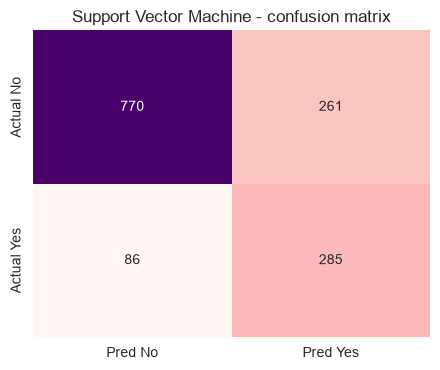

Best model by churn-F1: Support Vector Machine

              precision    recall  f1-score   support

          No       0.90      0.75      0.82      1031
         Yes       0.52      0.77      0.62       371

    accuracy                           0.75      1402
   macro avg       0.71      0.76      0.72      1402
weighted avg       0.80      0.75      0.76      1402



In [13]:
best_name = results["F1"].idxmax()
best = fitted[best_name]
pred = best.predict(X_test)
labels = list(best.classes_)

fig, ax = plt.subplots(figsize=(4.5, 3.8))
cm = confusion_matrix(y_test, pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="RdPu", cbar=False,
            xticklabels=[f"Pred {l}" for l in labels],
            yticklabels=[f"Actual {l}" for l in labels], ax=ax)
ax.set_title(f"{best_name} - confusion matrix")
plt.tight_layout(); plt.show()

print(f"Best model by churn-F1: {best_name}\n")
print(classification_report(y_test, pred, zero_division=0))

## 8. Observations

- The dataset is **imbalanced** (~27% churn), so plain accuracy is misleading - a model that
  predicts "No" for everyone already scores ~73%. **Churn-F1, AUC and MCC** are the honest
  yardsticks here.
- **No single model wins on every metric.** `class_weight='balanced'` lifts recall on
  churners (catching more of the customers who actually leave) at the cost of some precision
  and overall accuracy - exactly the trade-off a retention team would tune.
- **Contract type, tenure, internet service and lack of tech support** are the strongest
  churn signals visible in the EDA: month-to-month, fibre-optic, short-tenure customers churn
  far more often.
- All five models land in a fairly narrow band, which is typical for this well-studied
  dataset; the choice between them depends on whether the business values recall (find every
  churner) or precision (don't waste retention offers).